<a href="https://colab.research.google.com/github/moyaandres1099/Proyecto_Final/blob/main/Proyecto_final_documento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vinculación del patrimonio cultural del Territorio Huetar de Zapatón en el Plan de Manejo del Parque Nacional La Cangreja: contexto demográfico y análisis espacial

**Autor:** Andrés Moya Mata (B85455)
**Curso:** GF-0657 Programación en SIG, II ciclo 2026, Universidad de Costa Rica
**Proyecto final, segunda entrega: documento computacional**
**Fecha:** noviembre de 2026

## Resumen

El Territorio Indígena Huetar de Zapatón y el Parque Nacional La Cangreja se ubican en el cantón de Puriscal, provincia de San José, Costa Rica, y comparten un traslape que el Plan de Manejo del parque reporta en 68,05 ha. Este documento caracteriza ese contexto con datos abiertos y herramientas de Python (pandas, geopandas, matplotlib y folium). Con el Censo 2022 del INEC se describe la distribución de la población y de la densidad entre los nueve distritos de Puriscal y se perfilan Chires y Mercedes Sur. Con capas del IGN/SNIT y del SINAC se determina en qué distritos se localizan ambas áreas, qué ríos y quebradas las atraviesan o les son próximos (radio de 2 km) y cuánto mide su traslape en el sistema CRTM05 (EPSG:5367). Los resultados muestran que Zapatón queda totalmente en Chires, que el parque se reparte entre Chires (88 %) y Mercedes Sur (12 %), y que el traslape calculado es de 70,97 ha, 4,3 % mayor que el valor oficial. El documento incluye además la descripción de la aplicación web desarrollada en Streamlit.

## 1. Introducción

### 1.1 Tema y relevancia

El Territorio Indígena Huetar de Zapatón se localiza en el distrito de Chires, y el Parque Nacional La Cangreja comprende sectores de los distritos de Chires y Mercedes Sur, todos en el cantón de Puriscal. El parque fue creado en 2002 para proteger el Cerro La Cangreja, sus bosques y el recurso hídrico que allí nace (SINAC, 2018). La actualización de su Plan General de Manejo diagnosticó un traslape entre el área silvestre protegida y el territorio indígena, de 68,05 ha (SINAC, 2018).

La relevancia del tema es doble. Por un lado, el traslape plantea un reto de gobernanza entre una categoría de conservación y un territorio indígena, un derecho respaldado por el Convenio 169 de la OIT, que Costa Rica ratificó mediante la Ley N.° 7316 (Organización Internacional del Trabajo, 1989; Procuraduría General de la República, 1992). Por otro, según los actores locales consultados durante el trabajo práctico del autor en el SINAC, muchos de los sitios sagrados de la población Huetar de Zapatón surgen de ríos, nacientes, quebradas y cascadas. Por eso el análisis incluye la red hídrica próxima a ambas áreas.

### 1.2 Preguntas del proyecto

1. ¿Cómo se distribuyen la población y la densidad entre los distritos de Puriscal según el Censo 2022? (P1)
2. ¿Cómo se caracterizan demográficamente Chires (donde está Zapatón) y Mercedes Sur (donde está parte del parque)? (P2)
3. ¿En cuáles distritos se localizan el Territorio de Zapatón y el Parque Nacional La Cangreja, y cuántas hectáreas ocupan en cada uno? (P3)
4. ¿Qué ríos y quebradas atraviesan o se encuentran próximos a ambas áreas? (P4)
5. ¿Dónde está el traslape entre ambas áreas y cuánto mide? (P5)

### 1.3 Fuentes de datos

| Datos | Fuente | Acceso |
|---|---|---|
| Población y vivienda por distrito, Censo 2022 | Instituto Nacional de Estadística y Censos (2023) | CSV del curso (GF-0657, 2026) |
| Límites distritales | IGN / SNIT (s. f.) | Servicio ArcGIS REST |
| Territorios indígenas | SNIT (s. f.) | Servicio ArcGIS REST |
| Áreas silvestres protegidas | SINAC (2021) | Servicio ArcGIS REST |
| Ríos y quebradas | [SNIT (s. f.)] | Archivo `Datos/Rios.zip` en este repositorio |

### 1.4 Descripción de las tablas y capas

Los tipos de geometría, los SRC y el número de registros efectivamente cargados se muestran en la tabla de la sección 2.3, generada por el propio código. A continuación se resumen las variables principales.

- **Tabla de distritos (INEC):** sin geometría. Variables usadas: `codigo_canton`, `distrito`, `poblacion`, `densidad`, `hombres`, `mujeres`, `viviendas`, `viviendas_ocupadas`, `viviendas_desocupadas` y `tasa_crecimiento_poblacion`.
- **Distritos (IGN/SNIT):** polígonos. Variables: `nom_distr`, `cod_distr`, `canton`, `area_km2`.
- **Territorio de Zapatón (SNIT):** polígono. Variables: `Nombre`, `Pueblo`, `Poblacion`, `AreaOfi`, `DecrCreac`.
- **Parque Nacional La Cangreja (SINAC):** polígono. Variables: `nombre_asp`, `cat_manejo`, `area_km`.
- **Ríos y quebradas:** líneas. Variables: ver sección 2.3.

## 2. Datos y métodos

### 2.1 Bibliotecas y versiones

In [7]:
# Bibliotecas utilizadas
import io
import os
import sys
import zipfile
import tempfile
import unicodedata
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import folium

pd.set_option("display.max_colwidth", 80)

# Sistemas de referencia: geográfico para intercambio y CRTM05 (metros) para áreas y distancias
CRS_GEO = "EPSG:4326"
CRS_METRICO = "EPSG:5367"

versiones = {"Python": sys.version.split()[0]}
for paquete in ["pandas", "geopandas", "shapely", "matplotlib", "folium", "numpy", "requests"]:
    versiones[paquete] = version(paquete)

pd.DataFrame(versiones.items(), columns=["Biblioteca", "Versión"])

,Biblioteca,Versión
0,Python,3.14.6
1,pandas,3.0.5
2,geopandas,1.1.4
3,shapely,2.2.0
4,matplotlib,3.11.1
5,folium,0.20.0
6,numpy,2.5.1
7,requests,2.34.2


### 2.2 Carga y preparación de los datos

**Datos del Censo 2022.** Se cargan con pandas desde el CSV del curso y se filtra el cantón de Puriscal (código 104).

In [8]:
URL_INEC = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/inec/distritos-2022.csv"

distritos_inec = pd.read_csv(URL_INEC)

# Distritos del cantón de Puriscal (código de cantón 104)
puriscal_inec = distritos_inec[distritos_inec["codigo_canton"] == 104].copy()
puriscal_inec["distrito"] = puriscal_inec["distrito"].str.strip()

print(f"Distritos de Puriscal en la tabla del INEC: {len(puriscal_inec)}")
puriscal_inec[["distrito", "poblacion", "densidad", "tasa_crecimiento_poblacion"]].sort_values(
    "poblacion", ascending=False
).reset_index(drop=True)

Distritos de Puriscal en la tabla del INEC: 9


,distrito,poblacion,densidad,tasa_crecimiento_poblacion
0,Santiago,12189,353.1,0.52
1,Mercedes Sur,7056,38.8,1.68
2,Barbacoas,5104,274.1,2.94
3,San Antonio,4908,335.7,2.12
4,Chires,3022,13.2,-0.03
5,San Rafael,2156,139.1,2.00
6,Candelarita,1613,60.3,1.06
7,Grifo Alto,1570,59.5,2.58
8,Desamparaditos,907,125.6,2.81


**Capas geoespaciales.** Se descargan con geopandas desde servicios ArcGIS REST en formato GeoJSON, solicitando las coordenadas ya en EPSG:4326. La capa de territorios se filtra en el servidor por `Nombre = 'ZAPATÓN'`, porque pedir todos los territorios producía una respuesta truncada en pruebas anteriores. La capa de ríos es un archivo propio del proyecto, alojado en este repositorio y descargado también por URL.

In [9]:
def leer_arcgis(url, where="1=1"):
    """Descarga una capa de un servicio ArcGIS REST como GeoDataFrame en EPSG:4326."""
    parametros = {"where": where, "outFields": "*", "returnGeometry": "true",
                  "outSR": "4326", "f": "geojson"}
    respuesta = requests.get(url, params=parametros, timeout=180)
    respuesta.raise_for_status()
    datos = respuesta.json()
    if datos.get("exceededTransferLimit") or datos.get("properties", {}).get("exceededTransferLimit"):
        print("Aviso: el servicio truncó la respuesta:", url)
    return gpd.GeoDataFrame.from_features(datos["features"], crs=CRS_GEO)


URL_DISTRITOS = ("https://services5.arcgis.com/4u1m1BBDkNDTVWsd/arcgis/rest/services/"
                 "Distritos_CR/FeatureServer/0/query")
URL_TERRITORIOS = ("https://services1.arcgis.com/aWQmxJWy7lM2Qqmo/arcgis/rest/services/"
                   "CE_Publicos_CR/FeatureServer/4/query")
URL_ASP = ("https://services9.arcgis.com/RrvMEynxDB8hycVO/ArcGIS/rest/services/"
           "ÁSP_Costa_Rica_2021/FeatureServer/0/query")

distritos_cr = leer_arcgis(URL_DISTRITOS)
territorios = leer_arcgis(URL_TERRITORIOS, where="Nombre='ZAPATÓN'")
areas_protegidas = leer_arcgis(URL_ASP)

print("Distritos del país:", len(distritos_cr))
print("Territorios descargados:", len(territorios))
print("Áreas silvestres protegidas del país:", len(areas_protegidas))

Distritos del país: 487
Territorios descargados: 1
Áreas silvestres protegidas del país: 172


In [10]:
# Filtros: distritos de Puriscal, Territorio de Zapatón y Parque Nacional La Cangreja
distritos_puriscal = distritos_cr[distritos_cr["canton"].str.strip().str.upper() == "PURISCAL"].copy()
zapaton = territorios[territorios["Nombre"].str.strip().str.upper() == "ZAPATÓN"].copy()
cangreja = areas_protegidas[
    areas_protegidas["nombre_asp"].str.contains("La Cangreja", case=False, na=False)
].copy()


def reparar(gdf):
    """Corrige geometrías inválidas, que pueden dar errores en overlay."""
    gdf = gdf.copy()
    gdf["geometry"] = gdf.geometry.make_valid()
    return gdf


distritos_puriscal = reparar(distritos_puriscal)
zapaton = reparar(zapaton)
cangreja = reparar(cangreja)

print("Distritos de Puriscal:", len(distritos_puriscal))
print("Territorio de Zapatón:", len(zapaton))
print("Parque Nacional La Cangreja:", len(cangreja))

Distritos de Puriscal: 9
Territorio de Zapatón: 1
Parque Nacional La Cangreja: 1


**Unión de la tabla del INEC con los polígonos.** Los nombres de distrito difieren en mayúsculas entre ambas fuentes, por lo que se unen por una clave normalizada (sin tildes, en mayúsculas y sin espacios extra). Esto permite mapear las variables del censo.

In [11]:
def normalizar(texto):
    """Convierte a mayúsculas, sin tildes ni espacios sobrantes."""
    sin_tildes = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return sin_tildes.strip().upper()


puriscal_inec["clave"] = puriscal_inec["distrito"].map(normalizar)
distritos_puriscal["clave"] = distritos_puriscal["nom_distr"].map(normalizar)

columnas_censo = puriscal_inec[["clave", "poblacion", "densidad"]].rename(
    columns={"poblacion": "pob_2022", "densidad": "dens_2022"}
)
distritos_puriscal = distritos_puriscal.merge(columnas_censo, on="clave", how="left")

sin_union = distritos_puriscal["pob_2022"].isna().sum()
print(f"Distritos sin correspondencia en el INEC: {sin_union}")

Distritos sin correspondencia en el INEC: 0


In [12]:
# Capa de ríos y quebradas: archivo zip con el shapefile, alojado en este repositorio
URL_RIOS = "https://raw.githubusercontent.com/moyaandres1099/Proyecto_Final/main/Datos/Rios.zip"

respuesta = requests.get(URL_RIOS, timeout=180)
respuesta.raise_for_status()

carpeta_rios = tempfile.mkdtemp()
with zipfile.ZipFile(io.BytesIO(respuesta.content)) as zf:
    zf.extractall(carpeta_rios)

ruta_shp = [os.path.join(raiz, f) for raiz, _, archivos in os.walk(carpeta_rios)
            for f in archivos if f.lower().endswith(".shp")][0]

rios = gpd.read_file(ruta_shp)
print("Archivo leído:", os.path.basename(ruta_shp), "| registros:", len(rios), "| SRC:", rios.crs)

Archivo leído: Rios.shp | registros: 434 | SRC: EPSG:5367


### 2.3 Resumen de las capas cargadas

In [13]:
def resumen_capa(nombre, gdf):
    return {
        "Capa": nombre,
        "Registros": len(gdf),
        "Geometría": ", ".join(sorted(gdf.geom_type.unique())),
        "SRC": str(gdf.crs),
    }


pd.DataFrame([
    resumen_capa("Distritos de Puriscal (IGN/SNIT)", distritos_puriscal),
    resumen_capa("Territorio de Zapatón (SNIT)", zapaton),
    resumen_capa("Parque Nacional La Cangreja (SINAC)", cangreja),
    resumen_capa("Ríos y quebradas", rios),
])

,Capa,Registros,Geometría,SRC
0,Distritos de Puriscal (IGN/SNIT),9,Polygon,EPSG:4326
1,Territorio de Zapatón (SNIT),1,Polygon,EPSG:4326
2,Parque Nacional La Cangreja (SINAC),1,Polygon,EPSG:4326
3,Ríos y quebradas,434,LineString,EPSG:5367


In [14]:
# Atributos disponibles en la capa de ríos (para identificar la columna con el nombre)
print(rios.columns.tolist())

['nom_objeto', 'origen', 'codigo', 'nombre', 'orden', 'longitud', 'geometry']


### 2.4 Operaciones espaciales

Todas las áreas y distancias se calculan en **CRTM05 (EPSG:5367)**, un sistema proyectado en metros, no en grados. Las operaciones de relación topológica (unión espacial) se hacen entre capas en el mismo SRC.

| # | Operación | Pregunta que responde | SRC |
|---|---|---|---|
| 1 | Unión espacial (`sjoin`, predicado `intersects`) entre distritos y cada área | P3: ¿en cuáles distritos se localizan? | EPSG:4326 |
| 2 | Intersección (`overlay`) de cada área con los distritos, más `dissolve` y área | P3: ¿cuántas hectáreas en cada distrito? | EPSG:5367 |
| 3 | Área de influencia (`buffer` de 2 km) y selección con `intersects`, clasificando cada tramo | P4: ¿qué ríos atraviesan o están próximos? | EPSG:5367 |
| 4 | Intersección (`overlay`) entre Zapatón y La Cangreja, y área | P5: ¿dónde y cuánto es el traslape? | EPSG:5367 |

El radio de 2 km de la operación 3 es un criterio del autor para definir «próximo», no un valor oficial.

In [15]:
# Capas proyectadas a CRTM05 para medir áreas y distancias
dist_m = distritos_puriscal.to_crs(CRS_METRICO)
zap_m = zapaton.to_crs(CRS_METRICO)
cang_m = cangreja.to_crs(CRS_METRICO)
rios_m = rios.to_crs(CRS_METRICO)

dist_m["area_distrito_ha"] = dist_m.geometry.area / 10_000
print("Capas proyectadas a", CRS_METRICO)

Capas proyectadas a EPSG:5367


## 3. Resultados

### 3.1 Distribución de la población por distrito (P1)

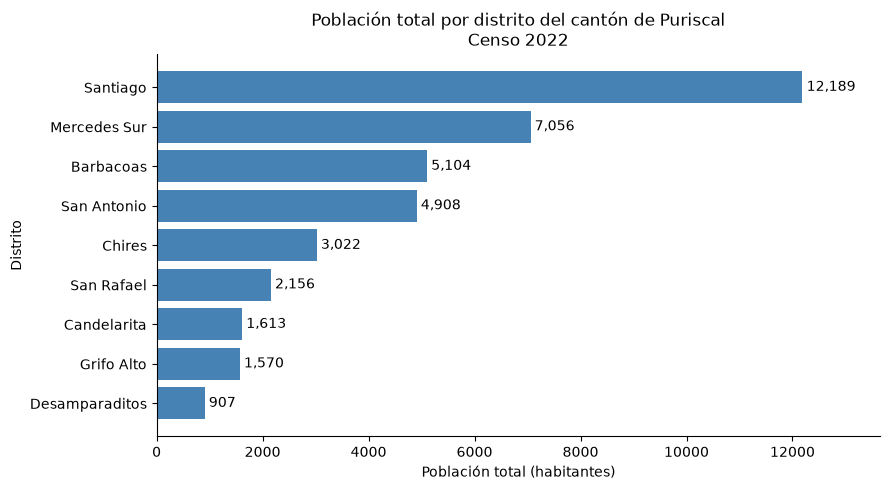

Población total de los nueve distritos: 38,525 habitantes


In [16]:
puriscal_pob = puriscal_inec.sort_values("poblacion", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(puriscal_pob["distrito"], puriscal_pob["poblacion"], color="steelblue")
ax.bar_label(barras, labels=[f"{v:,.0f}" for v in puriscal_pob["poblacion"]], padding=3)
ax.set_title("Población total por distrito del cantón de Puriscal\nCenso 2022")
ax.set_xlabel("Población total (habitantes)")
ax.set_ylabel("Distrito")
ax.set_xlim(0, puriscal_pob["poblacion"].max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

total_canton = puriscal_inec["poblacion"].sum()
print(f"Población total de los nueve distritos: {total_canton:,.0f} habitantes")

**Interpretación.** Santiago concentra la mayor población, con 12 189 habitantes, seguido de Mercedes Sur (7 056) y Barbacoas (5 104). Desamparaditos es el distrito menos poblado, con 907. Santiago reúne cerca del 32 % de los 38 525 habitantes del cantón y, junto con Mercedes Sur, aproximadamente la mitad. La distribución es, por tanto, muy desigual: unos pocos distritos concentran la población y varios tienen pesos mínimos. Chires, donde está el Territorio de Zapatón, tiene 3 022 habitantes.

### 3.2 Densidad de población por distrito (P1)

La densidad se muestra con barras y no con un gráfico circular, porque las densidades de distritos distintos no son partes de un mismo total y sus porcentajes no tienen sentido.

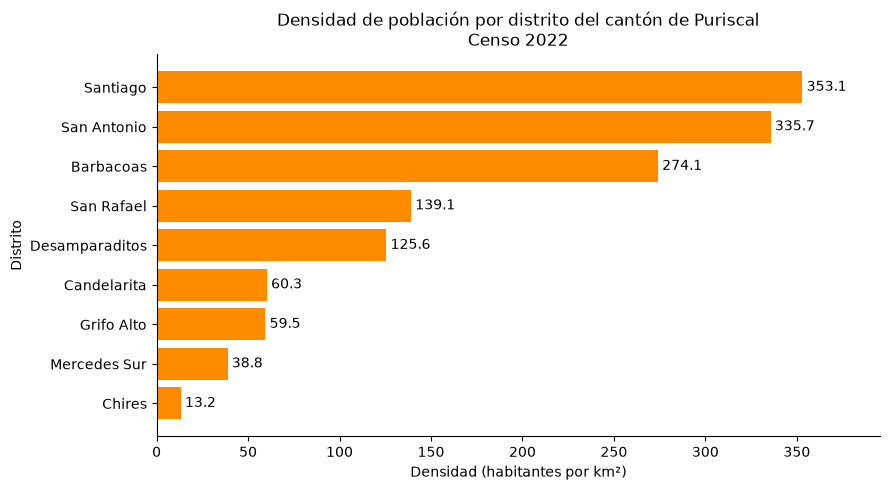

In [17]:
puriscal_dens = puriscal_inec.sort_values("densidad", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(puriscal_dens["distrito"], puriscal_dens["densidad"], color="darkorange")
ax.bar_label(barras, labels=[f"{v:,.1f}" for v in puriscal_dens["densidad"]], padding=3)
ax.set_title("Densidad de población por distrito del cantón de Puriscal\nCenso 2022")
ax.set_xlabel("Densidad (habitantes por km²)")
ax.set_ylabel("Distrito")
ax.set_xlim(0, puriscal_dens["densidad"].max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretación.** Santiago (353,1 hab/km²) y San Antonio (335,7 hab/km²) son los distritos más densos. En el otro extremo, Chires tiene la menor densidad del cantón (13,2 hab/km²), seguido de Mercedes Sur (38,8 hab/km²). El orden por densidad no coincide con el orden por población: San Antonio es muy denso pero poco poblado, por su territorio pequeño, y Mercedes Sur es el segundo más poblado pero uno de los menos densos, por su gran extensión. Precisamente los dos distritos que albergan el territorio indígena y el parque son los de ocupación más dispersa.

### 3.3 Caracterización demográfica de Chires y Mercedes Sur (P2)

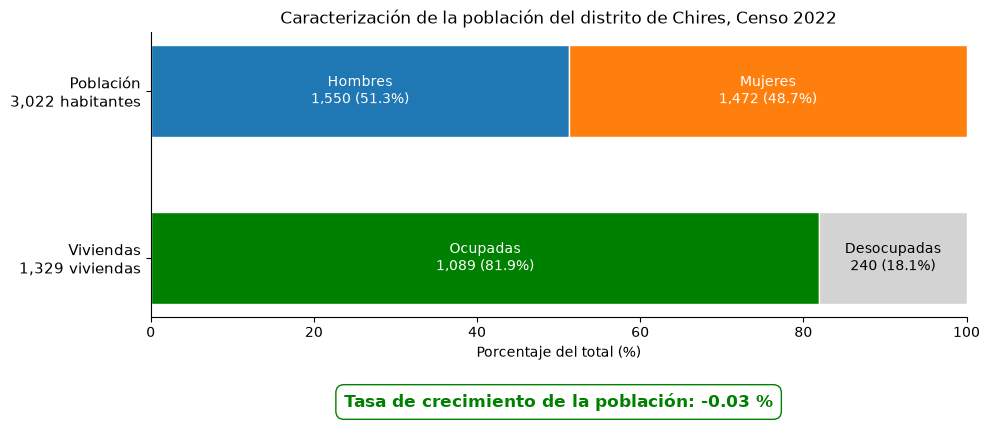

In [18]:
AZUL, NARANJA, VERDE, GRIS = "#1F77B4", "#FF7F0E", "green", "lightgray"


def perfil_distrito(nombre):
    """Dibuja dos barras al 100 %: población por sexo y viviendas por ocupación."""
    fila = distritos_inec[
        (distritos_inec["codigo_canton"] == 104) & (distritos_inec["distrito"].str.strip() == nombre)
    ].iloc[0]

    barras = {
        f"Población\n{fila['poblacion']:,.0f} habitantes": [
            ("Hombres", fila["hombres"], AZUL, "white"),
            ("Mujeres", fila["mujeres"], NARANJA, "white"),
        ],
        f"Viviendas\n{fila['viviendas']:,.0f} viviendas": [
            ("Ocupadas", fila["viviendas_ocupadas"], VERDE, "white"),
            ("Desocupadas", fila["viviendas_desocupadas"], GRIS, "black"),
        ],
    }

    fig, ax = plt.subplots(figsize=(10, 4.5))
    for i, (etiqueta, partes) in enumerate(barras.items()):
        total = sum(valor for _, valor, _, _ in partes)
        inicio = 0
        for parte, valor, color, color_texto in partes:
            pct = valor / total * 100
            ax.barh(i, pct, left=inicio, color=color, edgecolor="white", height=0.55)
            ax.text(inicio + pct / 2, i, f"{parte}\n{valor:,.0f} ({pct:.1f}%)",
                    ha="center", va="center", fontsize=10, color=color_texto)
            inicio += pct

    ax.set_yticks(range(len(barras)))
    ax.set_yticklabels(list(barras.keys()), fontsize=11)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Porcentaje del total (%)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(0.5, -0.30, f"Tasa de crecimiento de la población: {fila['tasa_crecimiento_poblacion']:.2f} %",
            transform=ax.transAxes, ha="center", va="center", fontsize=12, fontweight="bold",
            color=VERDE, bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": VERDE})
    ax.set_title(f"Caracterización de la población del distrito de {nombre}, Censo 2022")
    fig.tight_layout()
    plt.show()


perfil_distrito("Chires")

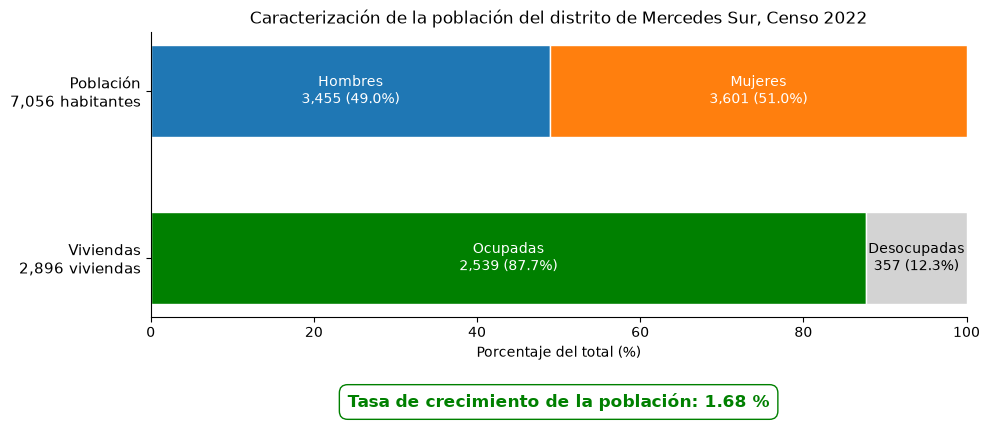

In [19]:
perfil_distrito("Mercedes Sur")

In [20]:
# Comparación de ambos distritos en una tabla
comparacion = puriscal_inec[puriscal_inec["distrito"].isin(["Chires", "Mercedes Sur"])].copy()
comparacion["% hombres"] = comparacion["hombres"] / comparacion["poblacion"] * 100
comparacion["% viviendas desocupadas"] = comparacion["viviendas_desocupadas"] / comparacion["viviendas"] * 100

comparacion[["distrito", "poblacion", "densidad", "% hombres", "viviendas",
             "% viviendas desocupadas", "tasa_crecimiento_poblacion"]].round(2).reset_index(drop=True)

,distrito,poblacion,densidad,% hombres,viviendas,% viviendas desocupadas,tasa_crecimiento_poblacion
0,Mercedes Sur,7056,38.8,48.97,2896.0,12.33,1.68
1,Chires,3022,13.2,51.29,1329.0,18.06,-0.03


**Interpretación.** Chires tiene 3 022 habitantes (51,3 % hombres y 48,7 % mujeres) y 1 329 viviendas, de las cuales 18,1 % están desocupadas, una proporción relativamente alta. Su tasa de crecimiento es de −0,03 %, lo que sugiere estancamiento demográfico. Mercedes Sur tiene 7 056 habitantes (49,0 % hombres y 51,0 % mujeres) y 2 896 viviendas, con 87,7 % ocupadas, y crece a 1,68 %. El distrito que alberga el territorio indígena no crece, mientras que el que comparte el parque sí.

### 3.4 Localización del Territorio y del Parque (P3)

**Operación 1: unión espacial.**

In [21]:
d_zapaton = gpd.sjoin(distritos_puriscal, zapaton[["geometry"]], how="inner", predicate="intersects")
d_cangreja = gpd.sjoin(distritos_puriscal, cangreja[["geometry"]], how="inner", predicate="intersects")

print("Distritos donde se localiza el Territorio de Zapatón:", sorted(d_zapaton["nom_distr"].unique()))
print("Distritos donde se localiza el Parque La Cangreja:   ", sorted(d_cangreja["nom_distr"].unique()))

Distritos donde se localiza el Territorio de Zapatón: ['CHIRES']
Distritos donde se localiza el Parque La Cangreja:    ['CHIRES', 'MERCEDES SUR']


**Operación 2: intersección con los distritos y área en hectáreas (CRTM05).** La suma por distrito se contrasta con el área total de cada capa como verificación.

In [22]:
def area_por_distrito(capa_m, nombre):
    inter = gpd.overlay(capa_m[["geometry"]], dist_m[["nom_distr", "geometry"]],
                        how="intersection", keep_geom_type=True)
    inter = inter.dissolve(by="nom_distr").reset_index()
    inter[f"{nombre}_ha"] = inter.geometry.area / 10_000
    return inter[["nom_distr", f"{nombre}_ha"]]


tabla = (
    dist_m[["nom_distr", "area_distrito_ha"]]
    .merge(area_por_distrito(zap_m, "zapaton"), on="nom_distr", how="left")
    .merge(area_por_distrito(cang_m, "cangreja"), on="nom_distr", how="left")
    .fillna(0)
)
tabla["% de Zapatón"] = tabla["zapaton_ha"] / tabla["zapaton_ha"].sum() * 100
tabla["% del parque"] = tabla["cangreja_ha"] / tabla["cangreja_ha"].sum() * 100
tabla["Zapatón (% del distrito)"] = tabla["zapaton_ha"] / tabla["area_distrito_ha"] * 100
tabla["Parque (% del distrito)"] = tabla["cangreja_ha"] / tabla["area_distrito_ha"] * 100

tabla_ocupada = tabla[(tabla["zapaton_ha"] > 0) | (tabla["cangreja_ha"] > 0)]
tabla_ocupada = tabla_ocupada.sort_values("cangreja_ha", ascending=False).round(2).reset_index(drop=True)
display(tabla_ocupada)

total_zap = zap_m.geometry.area.sum() / 10_000
total_cang = cang_m.geometry.area.sum() / 10_000
print(f"Zapatón:  capa = {total_zap:,.2f} ha | suma por distrito = {tabla['zapaton_ha'].sum():,.2f} ha")
print(f"La Cangreja: capa = {total_cang:,.2f} ha | suma por distrito = {tabla['cangreja_ha'].sum():,.2f} ha")

,nom_distr,area_distrito_ha,zapaton_ha,cangreja_ha,% de Zapatón,% del parque,Zapatón (% del distrito),Parque (% del distrito)
0,CHIRES,22965.85,3482.28,2270.59,100.0,88.23,15.16,9.89
1,MERCEDES SUR,18355.27,0.00,302.79,0.0,11.77,0.00,1.65


Zapatón:  capa = 3,498.00 ha | suma por distrito = 3,482.28 ha
La Cangreja: capa = 2,573.39 ha | suma por distrito = 2,573.39 ha


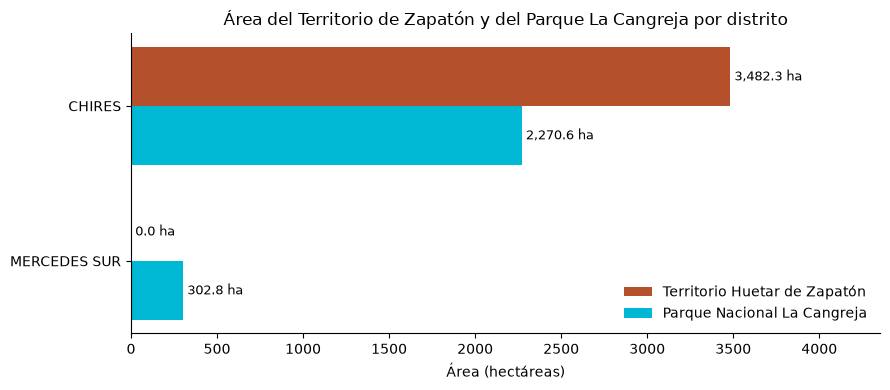

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(tabla_ocupada))
alto = 0.38
b1 = ax.barh(y - alto / 2, tabla_ocupada["zapaton_ha"], height=alto, color="#B5502D",
             label="Territorio Huetar de Zapatón")
b2 = ax.barh(y + alto / 2, tabla_ocupada["cangreja_ha"], height=alto, color="#00B8D4",
             label="Parque Nacional La Cangreja")
ax.bar_label(b1, labels=[f"{v:,.1f} ha" for v in tabla_ocupada["zapaton_ha"]], padding=3, fontsize=9)
ax.bar_label(b2, labels=[f"{v:,.1f} ha" for v in tabla_ocupada["cangreja_ha"]], padding=3, fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(tabla_ocupada["nom_distr"])
ax.invert_yaxis()
ax.set_xlabel("Área (hectáreas)")
ax.set_title("Área del Territorio de Zapatón y del Parque La Cangreja por distrito")
ax.set_xlim(0, tabla_ocupada[["zapaton_ha", "cangreja_ha"]].max().max() * 1.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Mapa estático de densidad de población con ambas áreas.** Cruza el censo con la geometría: cada distrito se colorea por su densidad (hab/km²) y se superponen los límites del territorio y del parque.

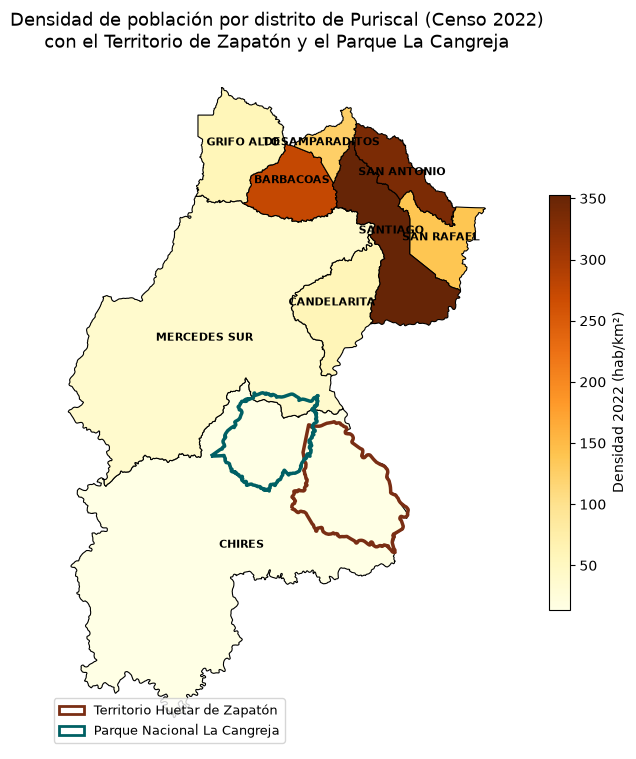

In [24]:
fig, ax = plt.subplots(figsize=(11, 9))

distritos_puriscal.plot(ax=ax, column="dens_2022", cmap="YlOrBr", edgecolor="black", linewidth=0.8,
                        legend=True, legend_kwds={"label": "Densidad 2022 (hab/km²)", "shrink": 0.6})
zapaton.boundary.plot(ax=ax, color="#7A2E14", linewidth=2.5)
cangreja.boundary.plot(ax=ax, color="#006064", linewidth=2.5)

for _, fila in distritos_puriscal.iterrows():
    punto = fila.geometry.representative_point()
    ax.annotate(fila["nom_distr"], xy=(punto.x, punto.y), ha="center", fontsize=8, weight="bold")

ax.legend(handles=[
    mpatches.Patch(facecolor="none", edgecolor="#7A2E14", linewidth=2, label="Territorio Huetar de Zapatón"),
    mpatches.Patch(facecolor="none", edgecolor="#006064", linewidth=2, label="Parque Nacional La Cangreja"),
], loc="lower left", fontsize=9)

ax.set_title("Densidad de población por distrito de Puriscal (Censo 2022)\n"
             "con el Territorio de Zapatón y el Parque La Cangreja", fontsize=13)
ax.set_axis_off()
plt.show()

**Interpretación.** El Territorio de Zapatón queda íntegramente en Chires, donde ocupa unas 3 482 ha, el 15,2 % del distrito. El Parque La Cangreja se reparte entre Chires (2 271 ha, 88,2 % del parque) y Mercedes Sur (303 ha, 11,8 %). Chires tiene 22 966 ha, de modo que el parque cubre cerca de 9,9 % del distrito, y en Mercedes Sur el parque ocupa 1,7 %. El mapa muestra que ambas áreas se ubican en los distritos de menor densidad del cantón, en el sector suroeste. La suma por distrito del Territorio (3 482,28 ha) es algo menor que el área de la capa (3 498,00 ha) y se discute en las limitaciones.

### 3.5 Ríos y quebradas próximos (P4)

**Operación 3: área de influencia de 2 km.** Se unen Zapatón y La Cangreja, se les aplica un buffer de 2 000 m en CRTM05 y se seleccionan los tramos que lo intersecan. Cada tramo se clasifica según atraviese una o ambas áreas, o solo sea próximo.

In [25]:
zap_union = zap_m.union_all()
cang_union = cang_m.union_all()
zona_influencia = gpd.GeoSeries([zap_union, cang_union], crs=CRS_METRICO).union_all().buffer(2000)

rios_cerca = rios_m[rios_m.intersects(zona_influencia)].copy()

# Columna con el nombre del río o quebrada (se detecta por palabras clave)
palabras = ["nombre", "nom_rio", "desc", "label", "fna", "toponimo"]
candidatas = [c for c in rios_cerca.columns if any(p in c.lower() for p in palabras)]
col_nombre = candidatas[0] if candidatas else rios_cerca.columns[0]
print("Columna usada como nombre:", col_nombre)

rios_cerca[col_nombre] = rios_cerca[col_nombre].fillna("Sin nombre oficial").astype(str)

en_zap = rios_cerca.intersects(zap_union)
en_cang = rios_cerca.intersects(cang_union)
rios_cerca["Relacion"] = np.select(
    [en_zap & en_cang, en_zap, en_cang],
    ["Atraviesa Zapatón y La Cangreja", "Atraviesa Zapatón", "Atraviesa La Cangreja"],
    default="Próximo (radio de 2 km)",
)
print("Tramos en el radio de 2 km:", len(rios_cerca))

Columna usada como nombre: nombre
Tramos en el radio de 2 km: 44


In [26]:
# Resumen compacto: número de tramos y de nombres distintos por tipo de relación
def nombres_resumidos(serie, maximo=12):
    nombres = sorted(serie.unique())
    texto = ", ".join(nombres[:maximo])
    return texto + (f" (+{len(nombres) - maximo} más)" if len(nombres) > maximo else "")


resumen_rios = (
    rios_cerca.groupby("Relacion")
    .agg(tramos=(col_nombre, "size"),
         nombres_distintos=(col_nombre, "nunique"),
         nombres=(col_nombre, nombres_resumidos))
    .reset_index()
)
resumen_rios

,Relacion,tramos,nombres_distintos,nombres
0,Atraviesa La Cangreja,5,5,"Quebrada Azul, Quebrada Estrella, Quebrada Grande, Quebrada Viento, Río Negro"
1,Atraviesa Zapatón,9,5,"Quebrada Bejuco, Quebrada Jucó, Quebrada Lajas, Río Candelaria, Río Rey"
2,Atraviesa Zapatón y La Cangreja,2,2,"Quebrada Fresca, Quebrada Guatuso"
3,Próximo (radio de 2 km),28,25,"Quebrada Achiote, Quebrada Bijagual, Quebrada Carate, Quebrada Colorado, Que..."


**Operación 4 y mapa web.** Antes del mapa web se calcula el traslape entre ambas áreas (P5), para incluirlo como capa.

### 3.6 Traslape entre el Territorio y el Parque (P5)

La intersección entre Zapatón y La Cangreja se calcula en CRTM05 y se compara con el valor de 68,05 ha reportado en el Plan de Manejo (SINAC, 2018).

In [27]:
traslape_m = gpd.overlay(zap_m[["geometry"]], cang_m[["geometry"]], how="intersection")
traslape_m = traslape_m[traslape_m.geom_type.isin(["Polygon", "MultiPolygon"])]

area_traslape = traslape_m.geometry.area.sum() / 10_000
area_oficial = 68.05
diferencia = area_traslape - area_oficial

print(f"Traslape calculado:    {area_traslape:,.2f} ha")
print(f"Traslape según SINAC:  {area_oficial:,.2f} ha")
print(f"Diferencia:            {diferencia:+,.2f} ha ({diferencia / area_oficial * 100:+.1f} %)")
print(f"Porcentaje de Zapatón: {area_traslape / total_zap * 100:.2f} %")
print(f"Porcentaje del parque: {area_traslape / total_cang * 100:.2f} %")

# Traslape por distrito
traslape_dist = gpd.overlay(traslape_m, dist_m[["nom_distr", "geometry"]], how="intersection")
traslape_dist["traslape_ha"] = traslape_dist.geometry.area / 10_000
traslape_dist.groupby("nom_distr")["traslape_ha"].sum().round(2).reset_index()

Traslape calculado:    70.97 ha
Traslape según SINAC:  68.05 ha
Diferencia:            +2.92 ha (+4.3 %)
Porcentaje de Zapatón: 2.03 %
Porcentaje del parque: 2.76 %


,nom_distr,traslape_ha
0,CHIRES,70.97


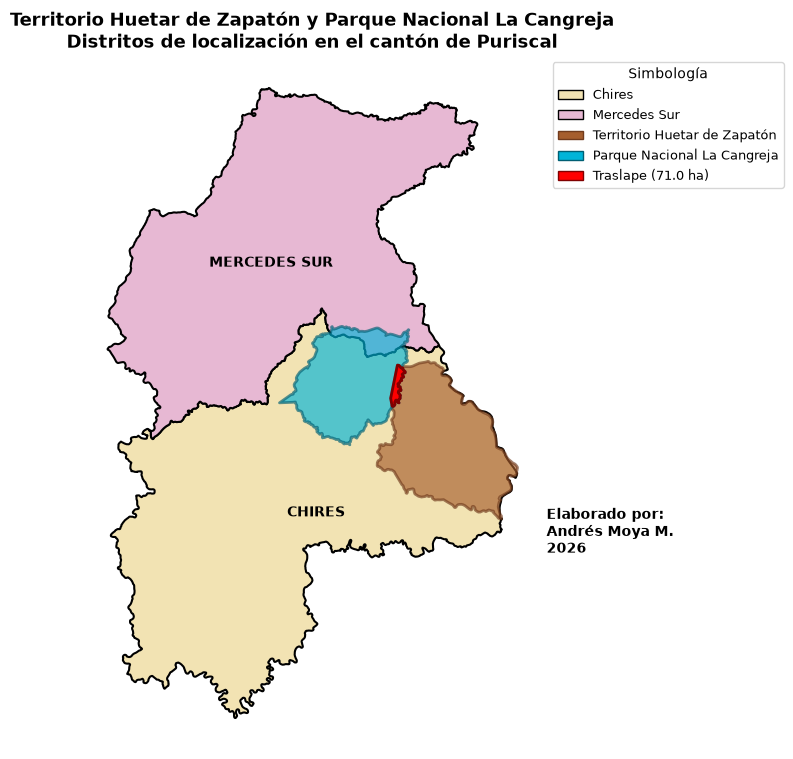

In [28]:
# Mapa estático de localización con el traslape (solo los distritos que contienen las áreas)
nombres_sel = sorted(set(d_zapaton["nom_distr"]) | set(d_cangreja["nom_distr"]))
dist_sel = distritos_puriscal[distritos_puriscal["nom_distr"].isin(nombres_sel)]
traslape = traslape_m.to_crs(CRS_GEO)

COLOR_DIST = {"CHIRES": "#F2E3B3", "MERCEDES SUR": "#E7B8D3"}

fig, ax = plt.subplots(figsize=(11, 9))
for _, fila in dist_sel.iterrows():
    gpd.GeoDataFrame([fila], crs=CRS_GEO).plot(
        ax=ax, facecolor=COLOR_DIST.get(fila["nom_distr"], "#DDDDDD"),
        edgecolor="black", linewidth=1.5, zorder=1)

zapaton.plot(ax=ax, facecolor="#A65E2E", edgecolor="#713B1D", linewidth=2, alpha=0.65, zorder=2)
cangreja.plot(ax=ax, facecolor="#00B4D8", edgecolor="#005F73", linewidth=2, alpha=0.65, zorder=3)
traslape.plot(ax=ax, facecolor="red", edgecolor="#800000", linewidth=2, zorder=4)

for _, fila in dist_sel.iterrows():
    punto = fila.geometry.representative_point()
    ax.annotate(fila["nom_distr"], xy=(punto.x, punto.y), ha="center", va="center",
                fontsize=10, weight="bold", zorder=5)

leyenda = [mpatches.Patch(facecolor=COLOR_DIST.get(n, "#DDDDDD"), edgecolor="black", label=n.title())
           for n in nombres_sel]
leyenda += [
    mpatches.Patch(facecolor="#A65E2E", edgecolor="#713B1D", label="Territorio Huetar de Zapatón"),
    mpatches.Patch(facecolor="#00B4D8", edgecolor="#005F73", label="Parque Nacional La Cangreja"),
    mpatches.Patch(facecolor="red", edgecolor="#800000", label=f"Traslape ({area_traslape:,.1f} ha)"),
]
ax.legend(handles=leyenda, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9, title="Simbología")
ax.text(1.02, 0.35, "Elaborado por:\nAndrés Moya M.\n2026", transform=ax.transAxes,
        fontsize=10, va="top", weight="bold")
ax.set_title("Territorio Huetar de Zapatón y Parque Nacional La Cangreja\n"
             "Distritos de localización en el cantón de Puriscal", fontsize=13, weight="bold")
fig.subplots_adjust(right=0.72)
ax.set_axis_off()
plt.show()

**Mapa web interactivo.** Reúne los distritos (con población y densidad), el Territorio, el Parque, el traslape y los tramos de ríos dentro del radio de 2 km, coloreados según su relación con las áreas. Se usan teselas de OpenStreetMap, porque las de CartoDB mostraron un aviso de clave de API en pruebas anteriores.

In [29]:
rios_web = rios_cerca.to_crs(CRS_GEO)[[col_nombre, "Relacion", "geometry"]]
dist_web = distritos_puriscal[["nom_distr", "pob_2022", "dens_2022", "geometry"]]
zap_web = zapaton[["Nombre", "Pueblo", "geometry"]]
cang_web = cangreja[["nombre_asp", "cat_manejo", "geometry"]]
tras_web = gpd.GeoDataFrame({"Nombre": ["Traslape"]}, geometry=[traslape.geometry.union_all()], crs=CRS_GEO)

mapa = dist_web.explore(
    name="Distritos de Puriscal", color="gray",
    style_kwds={"fillOpacity": 0.05, "weight": 1},
    tooltip=["nom_distr", "pob_2022", "dens_2022"], tiles="OpenStreetMap",
)
zap_web.explore(m=mapa, name="Territorio de Zapatón", color="darkorange",
                style_kwds={"fillOpacity": 0.4, "weight": 2}, tooltip=["Nombre", "Pueblo"])
cang_web.explore(m=mapa, name="Parque Nacional La Cangreja", color="forestgreen",
                 style_kwds={"fillOpacity": 0.4, "weight": 2}, tooltip=["nombre_asp", "cat_manejo"])
tras_web.explore(m=mapa, name="Traslape", color="red",
                 style_kwds={"fillOpacity": 0.8, "weight": 2}, tooltip=["Nombre"])
rios_web.explore(m=mapa, name="Ríos y quebradas (2 km)", column="Relacion", cmap="Set1",
                 legend=True, style_kwds={"weight": 3}, tooltip=[col_nombre, "Relacion"])

folium.LayerControl(collapsed=False).add_to(mapa)
mapa

**Interpretación.** El mapa interactivo permite ver qué cauces atraviesan el Territorio de Zapatón, cuáles el parque y cuáles ambos. En el análisis previo del autor, los cauces que atraviesan solo Zapatón incluyeron los ríos Candelaria, Rey, Bejuco, Jucó y Lajas; los que atraviesan solo el parque, el Azul, el Estrella y el Grande; y los que atraviesan ambas áreas, el Guatuso y el Fresca [VERIFICAR contra la tabla de resumen al ejecutar el cuaderno]. La tabla de resumen reporta cuántos tramos y cuántos nombres distintos hay por categoría. Los cauces que cruzan ambas áreas son relevantes para la gestión compartida, porque enlazan los dos espacios. Esto conecta con el contexto cultural: los sitios sagrados de la población Huetar se asocian a cauces y cascadas, como la Catarata El Rey, y el parque protege las nacientes de varios de ellos.

La capa de ríos solo permite afirmar cercanía y cruce, no relación cultural. Los sitios sagrados no están georreferenciados en los datos disponibles.

**Interpretación del traslape.** El traslape calculado es de 70,97 ha, ubicadas por completo en Chires. Es 2,92 ha (4,3 %) mayor que las 68,05 ha del Plan de Manejo, y equivale a cerca del 2,0 % del Territorio y del 2,8 % del Parque. Es una superficie pequeña en términos relativos, pero real, y es el punto donde el plan de manejo necesitaría un esquema de gobernanza compartida.

## 4. La aplicación

**Aplicación publicada:** <https://proyectofinal-kxq2zswpaoxrbr7yquhkh2.streamlit.app/>
**Repositorio:** <https://github.com/moyaandres1099/Proyecto_Final>

### 4.1 Propósito y estructura

La aplicación, desarrollada con Streamlit y publicada en Streamlit Community Cloud, contextualiza el área de estudio de mi tesis. Muestra la ubicación del Territorio de Zapatón y del Parque La Cangreja dentro del cantón de Puriscal, los distritos que abarcan y datos poblacionales del cantón segmentados por distrito. Carga las mismas fuentes de este documento: el CSV de distritos del INEC y las capas de distritos (IGN/SNIT), territorios indígenas (SNIT) y áreas silvestres protegidas (SINAC) desde sus URL. El repositorio contiene la carpeta `apps/`, el archivo `requirements.txt` y el `README.md`.

> **[a partir de `apps/`]**
> - **Controles:** Posee un de distritos para poder seleccionarlos o eliminarlos y que se muestren ya sea en la tabla, gráficos o los mapas. Por otra parte posee una vara para filtrar datos según la población minima de habitants y las variables que colorean el mapa ya sea según la población total, densidad poblacional o la tasa de crecimiento, todo esto esta al lado izquierdo. Y los controles ya dentro del contexto de la pagina que nos moviliza ya sea a la tabla, a los gráficos y al mapa.
> - **Qué muestra:** mapas, gráficos y tablas que aparecen y cómo cambian con los controles.

### 4.2 Captura de pantalla

![Captura de la aplicación](https://raw.githubusercontent.com/moyaandres1099/Proyecto_Final/main/captura_app.png)


### 4.3 Decisiones de diseño

> Pense principalmente que la app puede llegar a cualquier tipo de persona, no solo profesionales, y por ende tal vez la facilidad de uso de este tipo de apps interactivas les cueste. Por ende escogi esos botones y la forma en la que los coloque, para hacer de la app facil de utilizar y explorar, lo organice en un word y le pedi ayuda a la IA (Gemini en este caso) para motarlo

### 4.4 Problemas encontrados y soluciones

> No entendia bien lasdependencias en `requirements.txt`, y no lo estaba subiendo al read.me entonces estaba teniendo problemas con eso. La solución la encontre con la IA  revisando la pagina del curso

## 5. Conclusiones

**Respuestas a las preguntas del proyecto**

1. **Población y densidad (P1).** La población de Puriscal está muy concentrada: Santiago reúne cerca del 32 % de los 38 525 habitantes y, con Mercedes Sur, aproximadamente la mitad. El orden por densidad difiere del orden por población: Santiago (353,1 hab/km²) y San Antonio (335,7) son los más densos, y Chires (13,2) y Mercedes Sur (38,8) los menos.
2. **Chires y Mercedes Sur (P2).** Chires tiene 3 022 habitantes, tasa de crecimiento de −0,03 % y 18,1 % de viviendas desocupadas. Mercedes Sur tiene 7 056 habitantes, crece 1,68 % y tiene 87,7 % de viviendas ocupadas.
3. **Localización (P3).** Zapatón está totalmente en Chires (≈3 482 ha, 15,2 % del distrito). El parque se reparte entre Chires (2 271 ha, 88 %) y Mercedes Sur (303 ha, 12 %).
4. **Ríos y quebradas (P4).** Dentro de un radio de 2 km hay numerosos tramos de cauces, clasificados según atraviesen Zapatón, el parque, ambos o solo sean próximos. Se identificaron cauces que conectan ambas áreas.
5. **Traslape (P5).** La intersección calculada es de 70,97 ha, todas en Chires, 4,3 % más que el valor del Plan de Manejo (68,05 ha); equivale a cerca del 2 % de Zapatón y del 2,8 % del parque.



## 6. Referencias bibliográficas

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Instituto Geográfico Nacional. (s. f.). *Distritos_CR* [Capa geoespacial, servicio ArcGIS REST]. Sistema Nacional de Información Territorial. https://services5.arcgis.com/4u1m1BBDkNDTVWsd/arcgis/rest/services/Distritos_CR/FeatureServer/0

Instituto Geográfico Nacional. (s. f.). *Rios* [Capa geoespacial, servicio ArcGIS REST]. Sistema Nacional de Información Territorial.

Instituto Nacional de Estadística y Censos. (2023). *Resultados Estimación de Población y Vivienda 2022* [Conjunto de datos]. https://admin.inec.cr/sites/default/files/2023-11/reResultadosEstimacionPoblacionVivienda2022_3.xlsx

Jordahl, K., Van den Bossche, J., Fleischmann, M., Wasserman, J., McBride, J., Gerard, J., Tratner, J., Perry, M., Badaracco, A. G., Farmer, C., Hjelle, G. A., Snow, A. D., Cochran, M., Gillies, S., Culbertson, L., Bartos, M., Eubank, N., maxalbert, Bilogur, A., … Leblanc, F. (2020). *geopandas/geopandas: v0.8.1* [Software]. Zenodo. https://doi.org/10.5281/zenodo.3946761

McKinney, W. (2010). Data structures for statistical computing in Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56-61). https://doi.org/10.25080/Majora-92bf1922-00a

Organización Internacional del Trabajo. (1989). *Convenio sobre pueblos indígenas y tribales, 1989 (núm. 169)*. https://www.ohchr.org/es/instruments-mechanisms/instruments/indigenous-and-tribal-peoples-convention-1989-no-169

Procuraduría General de la República. (1992). *Convenio N.° 169 sobre pueblos indígenas y tribales en países independientes, Ley N.° 7316*. Costa Rica.

Programación en Sistemas de Información Geográfica. (2026). *GF-0657 Programación en SIG, 2026-II* [Sitio web del curso y datos]. Universidad de Costa Rica. https://gf0657-programacionsig.github.io/2026-ii/

Python Visualization. (s. f.). *Folium documentation*. https://python-visualization.github.io/folium/

Sistema Nacional de Áreas de Conservación. (2018). *Actualización del Plan General de Manejo del Parque Nacional La Cangreja*. Área de Conservación Cordillera Central.

Sistema Nacional de Áreas de Conservación. (2021). *ÁSP Costa Rica 2021* [Capa geoespacial, servicio ArcGIS REST]. https://services9.arcgis.com/RrvMEynxDB8hycVO/ArcGIS/rest/services/%C3%81SP_Costa_Rica_2021/FeatureServer/0

Sistema Nacional de Información Territorial. (s. f.). *CE_Publicos_CR: Territorios indígenas* [Capa geoespacial, servicio ArcGIS REST]. https://services1.arcgis.com/aWQmxJWy7lM2Qqmo/arcgis/rest/services/CE_Publicos_CR/FeatureServer/4

Streamlit Inc. (s. f.). *Streamlit documentation*. https://docs.streamlit.io/



## 7. Declaración de uso de asistentes de inteligencia artificial

| Herramienta | Propósito | Partes del trabajo |
|---|---|---|
| Claude (Anthropic) | Reorganizar y comentar código;  revisar texto. | Todo el cuaderno |
| ChatGPT, Claude y Gemini | Corrección y mejora de código, búsqueda de información (en particular de las fuentes de datos geoespaciales) y apoyo en la redacción. | Tareas 2 y 3, y la aplicación en Streamlit |

